# Exploratory Data Analysis — BRFSS 2012

**Project:** Diabetes Prediction Using Machine Learning  
**Dataset:** CDC Behavioral Risk Factor Surveillance System (2012)

## Objective

Explore the characteristics, quality, distributions, and relationships of the BRFSS 2012 survey data, with a particular focus on diabetes prediction.

This notebook contains:
- Descriptive statistics and visualizations
- Missing-value analysis
- BRFSS special-code decoding
- Univariate and bivariate analysis
- Correlation analysis
- Data-quality observations
- Conclusions and recommendations


**Dataset:** 475,687 respondents × 359 variables.

## 1. Load the data

Each row represents one survey respondent. Columns represent survey questions or calculated variables.

The dataset is large, so loading may take some time.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)

PALETTE = [
    '#2a78d6', '#eb6834', '#1baf7a',
    '#eda100', '#e87ba4', '#6250d6'
]
BLUE = PALETTE[0]

sns.set_theme(style='whitegrid', palette=PALETTE)
plt.rcParams.update({
    'figure.dpi': 100,
    'axes.spines.top': False,
    'axes.spines.right': False
})

df = pd.read_csv('2012.csv', low_memory=False)

print(f'{df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Memory: {df.memory_usage(deep=True).sum()/1e9:.2f} GB')

display(df.head())

475,687 rows × 359 columns
Memory: 1.40 GB


,_STATE,_GEOSTR,_DENSTR2,PRECALL,REPNUM,REPDEPTH,FMONTH,IDATE,IMONTH,IDAY,IYEAR,INTVID,DISPCODE,SEQNO,_PSU,NATTMPTS,NRECSEL,NRECSTR,CTELENUM,PVTRESID,COLGHOUS,CELLFON,LADULT,NUMADULT,NUMMEN,...,_RFBMI5,_CHLDCNT,_EDUCAG,_INCOMG,_SMOKER3,_RFSMOK3,DRNKANY5,DROCDY3_,_RFBING5,_DRNKDY4,_DRNKMO4,_RFDRHV4,_RFDRMN4,_RFDRWM4,_FLSHOT5,_PNEUMO2,_RFSEAT2,_RFSEAT3,_RFMAM2Y,_MAM502Y,_RFPAP32,_RFPSA21,_RFBLDS2,_RFSIGM2,_AIDTST3
0,1.0,7.0,1.0,1.0,20118.0,3.0,2.0,b'02162012',b'02',b'16',b'2012',b'00163',1100.0,2.012001e+09,2.012001e+09,8.0,2585.0,45328.0,1.0,1.0,NaN,1.0,NaN,2.0,1.000000e+00,...,2.0,3.0,3.0,4.0,4.0,1.0,2.0,5.397605e-79,1.0,5.397605e-79,5.397605e-79,1.0,1.0,NaN,NaN,NaN,1.0,1.0,NaN,NaN,NaN,1.0,1.0,2.0,2.0
1,1.0,8.0,1.0,1.0,10119.0,17.0,1.0,b'01052012',b'01',b'05',b'2012',b'00172',1100.0,2.012001e+09,2.012001e+09,2.0,3284.0,162814.0,1.0,1.0,NaN,1.0,NaN,4.0,1.000000e+00,...,2.0,1.0,4.0,5.0,4.0,1.0,1.0,1.000000e+01,1.0,2.000000e+01,6.000000e+00,1.0,1.0,NaN,NaN,NaN,1.0,1.0,NaN,NaN,NaN,1.0,2.0,1.0,1.0
2,1.0,8.0,2.0,1.0,10126.0,5.0,1.0,b'01032012',b'01',b'03',b'2012',b'00105',1100.0,2.012001e+09,2.012001e+09,1.0,5535.0,399986.0,1.0,1.0,NaN,1.0,NaN,1.0,5.397605e-79,...,2.0,1.0,4.0,9.0,3.0,1.0,1.0,7.000000e+00,1.0,9.900000e+03,9.999000e+03,9.0,NaN,9.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,9.0,1.0,2.0
3,1.0,8.0,1.0,1.0,10128.0,9.0,1.0,b'01192012',b'01',b'19',b'2012',b'00106',1100.0,2.012001e+09,2.012001e+09,2.0,3284.0,162814.0,1.0,1.0,NaN,1.0,NaN,2.0,1.000000e+00,...,1.0,1.0,1.0,2.0,4.0,1.0,2.0,5.397605e-79,1.0,5.397605e-79,5.397605e-79,1.0,NaN,1.0,2.0,2.0,1.0,1.0,1.0,1.0,NaN,NaN,2.0,2.0,2.0
4,1.0,8.0,1.0,1.0,10130.0,26.0,1.0,b'01062012',b'01',b'06',b'2012',b'00102',1100.0,2.012001e+09,2.012001e+09,1.0,3284.0,162814.0,1.0,1.0,NaN,1.0,NaN,2.0,1.000000e+00,...,2.0,1.0,2.0,9.0,4.0,1.0,2.0,5.397605e-79,1.0,5.397605e-79,5.397605e-79,1.0,NaN,1.0,NaN,NaN,1.0,1.0,1.0,1.0,NaN,NaN,2.0,1.0,2.0


### Remark

The diagnostic report confirms **475,687 rows and 359 columns**.

BRFSS contains both health-related questions and administrative information. Not every column is relevant to diabetes prediction.

## 2. Column types

Most survey responses are represented by numerical codes, even when they describe categories.

For example, `SEX` uses numerical codes for categories rather than continuous measurements.

In [2]:
print(df.dtypes.value_counts())

print('\nNon-numeric columns:')
print(df.select_dtypes(exclude='number').columns.tolist())

float64    347
str         12
Name: count, dtype: int64

Non-numeric columns:
['IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'INTVID', 'MRACE', 'PCDMDECN', 'RCSBIRTH', 'RCSRACE', 'RCVFVCH4', 'CRACEORG', 'MRACEORG']


### Remark

A numeric data type does not necessarily mean a variable is quantitative.

We must distinguish:
- **Continuous:** BMI
- **Ordinal:** general health, education, income groups
- **Nominal:** sex, state
- **Binary:** exercise status, history of certain diseases

## 3. Missing values

### 3.1 Overall missingness

BRFSS includes optional modules and questions asked only to certain respondents. This creates substantial structural missingness.

In [3]:
missing = df.isna().mean().sort_values(ascending=False)

total_cells = df.size
empty_cells = int(df.isna().sum().sum())

print(f'Total cells: {total_cells:,}')
print(f'Empty cells: {empty_cells:,}')
print(f'Overall missingness: {empty_cells/total_cells:.2%}')
print(f'Columns with no missing values: {(missing == 0).sum()}')
print(f'Columns > 50% missing: {(missing > .5).sum()}')
print(f'Columns > 90% missing: {(missing > .9).sum()}')

display(missing.head(20).to_frame('Missing fraction'))

Total cells: 170,771,633
Empty cells: 87,864,646
Overall missingness: 51.45%
Columns with no missing values: 80
Columns > 50% missing: 198
Columns > 90% missing: 121


,Missing fraction
EMTSUPRT,1.000000
LSATISFY,1.000000
VHCOMBAT,1.000000
VHDRPTSD,1.000000
VHCOUNSL,1.000000
VHDRTBI,1.000000
HAVHPAD,1.000000
DRHPAD1,1.000000
WRKHCF1,1.000000
DIRCONT1,1.000000


### Observation

The diagnostic report found:

- **87,864,646 missing cells (51.45%)**
- **198 columns** with more than 50% missing values
- **121 columns** with more than 90% missing values

These percentages concern the complete 359-column dataset, not just the variables selected for diabetes prediction.

**Decision:** We should not use `df.dropna()` on the entire dataset. Instead, we should select relevant features and analyze their missing values separately.

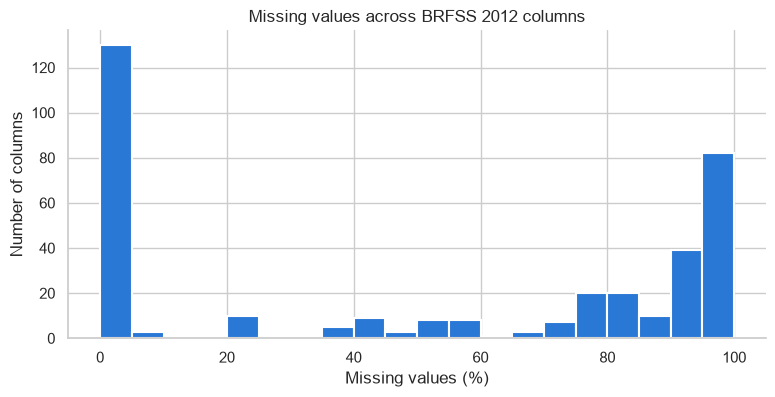

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(missing * 100, bins=20, color=BLUE,
        edgecolor='white', linewidth=1.5)

ax.set(
    title='Missing values across BRFSS 2012 columns',
    xlabel='Missing values (%)',
    ylabel='Number of columns'
)

plt.show()

## 4. Select relevant health variables

We focus on variables useful for understanding diabetes, health, lifestyle, and demographics.

The 2012 dataset does not contain every variable used in the 2015 example.

For instance, `_RFHYPE5`, `BPHIGH4`, and `TOLDHI2` are unavailable in this file.

In [5]:
candidate_cols = [
    '_STATE', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH',
    '_BMI5', 'SEX', '_AGEG5YR', '_EDUCAG',
    '_INCOMG', '_SMOKER3', 'DIABETE3',
    'CVDINFR4', 'EXERANY2', 'CVDSTRK3',
    'CHCKIDNY', 'HLTHPLN1', 'MEDCOST',
    'MARITAL', '_LLCPWT'
]

available = [c for c in candidate_cols if c in df.columns]
unavailable = [c for c in candidate_cols if c not in df.columns]

print('Available:', available)
print('Unavailable:', unavailable)

d = df[available].copy()
display(d.head())

Available: ['_STATE', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', '_BMI5', 'SEX', '_AGEG5YR', '_EDUCAG', '_INCOMG', '_SMOKER3', 'DIABETE3', 'CVDINFR4', 'EXERANY2', 'CVDSTRK3', 'CHCKIDNY', 'HLTHPLN1', 'MEDCOST', 'MARITAL', '_LLCPWT']
Unavailable: []


,_STATE,GENHLTH,PHYSHLTH,MENTHLTH,_BMI5,SEX,_AGEG5YR,_EDUCAG,_INCOMG,_SMOKER3,DIABETE3,CVDINFR4,EXERANY2,CVDSTRK3,CHCKIDNY,HLTHPLN1,MEDCOST,MARITAL,_LLCPWT
0,1.0,3.0,77.0,88.0,2577.0,1.0,9.0,3.0,4.0,4.0,3.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,246.877285
1,1.0,1.0,88.0,88.0,2825.0,1.0,7.0,4.0,5.0,4.0,3.0,2.0,1.0,2.0,2.0,1.0,2.0,1.0,898.578096
2,1.0,4.0,2.0,2.0,3916.0,2.0,10.0,4.0,9.0,3.0,3.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,110.334175
3,1.0,3.0,88.0,88.0,2413.0,2.0,11.0,1.0,2.0,4.0,3.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,395.063376
4,1.0,4.0,15.0,88.0,4600.0,2.0,9.0,2.0,9.0,4.0,1.0,2.0,1.0,2.0,2.0,1.0,2.0,1.0,460.536367


## 5. Decode special BRFSS values

BRFSS stores certain answers as special numeric codes.

Examples:
- `7` or `77`: Don't know / Not sure
- `9` or `99`: Refused
- `88`: None, representing zero days in certain health questions

**Important:** Codes must be decoded column by column. A value of `7` or `9` can be valid in other variables.


In [6]:
invalid_codes = {
    'GENHLTH': [7, 9],
    'DIABETE3': [7, 9],
    'CVDINFR4': [7, 9],
    'CVDSTRK3': [7, 9],
    'CHCKIDNY': [7, 9],
    'EXERANY2': [7, 9],
    'HLTHPLN1': [7, 9],
    'MEDCOST': [7, 9],
    'MARITAL': [9],
    '_AGEG5YR': [14],
    '_EDUCAG': [9],
    '_INCOMG': [9],
    '_SMOKER3': [9],
    'PHYSHLTH': [77, 99],
    'MENTHLTH': [77, 99]
}

for col, codes in invalid_codes.items():
    if col in d.columns:
        d[col] = d[col].replace(codes, np.nan)

for col in ['PHYSHLTH', 'MENTHLTH']:
    d[col] = d[col].replace(88, 0)

d['BMI'] = d.pop('_BMI5') / 100

### Observation

The diagnostic results showed:

- `PHYSHLTH`: **294,164** respondents answered `88` (no days of poor physical health).
- `MENTHLTH`: **319,143** respondents answered `88` (no days of poor mental health).
- `_INCOMG`: **66,745** responses were coded `9` (missing income information).
- `_AGEG5YR`: **4,580** responses were coded `14` (missing age group).

These codes would distort statistics if interpreted as ordinary measurements.

**Decision:** Use the decoded copy `d` for EDA while preserving the original `df`.

## 6. Diabetes target distribution

`DIABETE3` describes respondents' self-reported diabetes status:

| Code | Meaning |
|---|---|
| 1 | Diabetes |
| 2 | Diabetes during pregnancy only |
| 3 | No diabetes |
| 4 | Pre-diabetes |
| 7 / 9 | Unknown / refused |

For now, we preserve the original four meaningful categories.

,Count,Percentage
Diabetes_status,,
No diabetes,403299,84.93
Diabetes,59763,12.59
Pre-diabetes,7735,1.63
Pregnancy only,4067,0.86


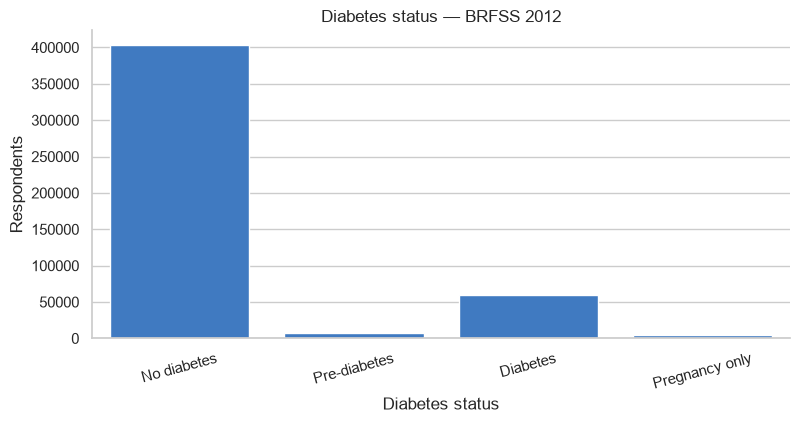

In [7]:
diabetes_labels = {
    1: 'Diabetes',
    2: 'Pregnancy only',
    3: 'No diabetes',
    4: 'Pre-diabetes'
}

d['Diabetes_status'] = d['DIABETE3'].map(diabetes_labels)

counts = d['Diabetes_status'].value_counts()
percentages = d['Diabetes_status'].value_counts(normalize=True) * 100

display(pd.DataFrame({
    'Count': counts,
    'Percentage': percentages.round(2)
}))

order_diabetes = [
    'No diabetes', 'Pre-diabetes',
    'Diabetes', 'Pregnancy only'
]

fig, ax = plt.subplots(figsize=(9, 4))

sns.countplot(
    data=d,
    x='Diabetes_status',
    order=order_diabetes,
    color=BLUE,
    ax=ax
)

ax.set(
    title='Diabetes status — BRFSS 2012',
    xlabel='Diabetes status',
    ylabel='Respondents'
)
ax.tick_params(axis='x', rotation=15)

plt.show()

### Observation

According to the complete dataset:

| Category | Respondents | Approximate share |
|---|---:|---:|
| No diabetes | 403,299 | 84.78% |
| Diabetes | 59,763 | 12.56% |
| Pre-diabetes | 7,735 | 1.63% |
| Pregnancy only | 4,067 | 0.85% |
| Unknown / refused | 823 | 0.17% |

**Interpretation:** The target is strongly imbalanced. Most respondents report no diabetes, while the pre-diabetes class is particularly small.

For machine learning, accuracy alone would be misleading. Class-specific recall, precision, F1-score, and a confusion matrix will be important.

The treatment of pregnancy-only diabetes is a modeling decision that must be documented.

## 7. Numeric summary

We study BMI and the number of days of poor physical or mental health in the previous 30 days.

In [8]:
numeric_cols = ['BMI', 'PHYSHLTH', 'MENTHLTH']

display(d[numeric_cols].describe().round(2))

,BMI,PHYSHLTH,MENTHLTH
count,450212.00,465792.00,467669.00
mean,27.72,4.39,3.51
std,6.05,8.91,7.84
min,12.02,0.00,0.00
25%,23.63,0.00,0.00
50%,26.63,0.00,0.00
75%,30.67,3.00,2.00
max,98.91,30.00,30.00


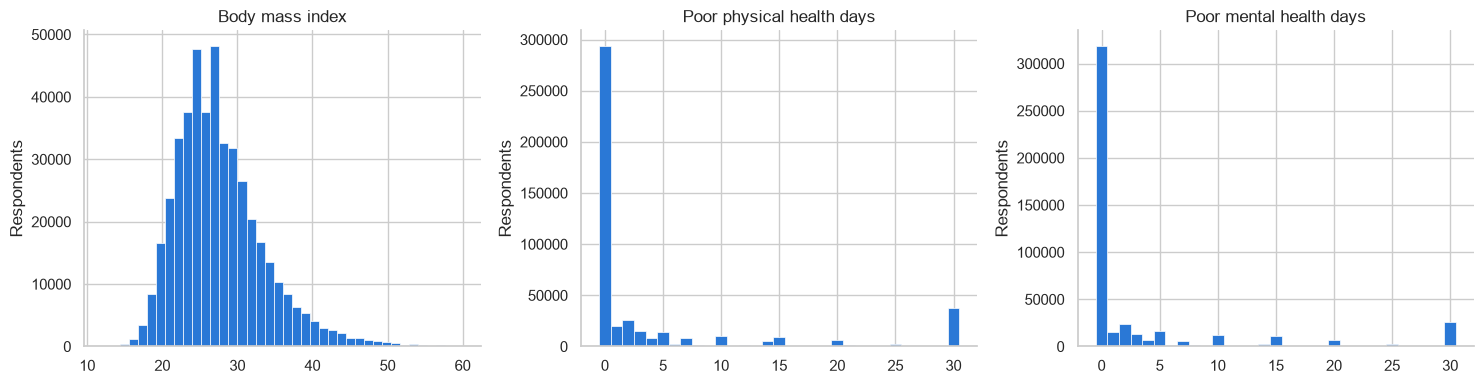

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

specs = [
    ('BMI', 'Body mass index', (12, 60)),
    ('PHYSHLTH', 'Poor physical health days', (0, 30)),
    ('MENTHLTH', 'Poor mental health days', (0, 30))
]

for ax, (col, title, limits) in zip(axes, specs):
    values = d[col].dropna()

    if col == 'BMI':
        values = values[values.between(*limits)]
        bins = 40
    else:
        bins = np.arange(-0.5, 31.5, 1)

    ax.hist(values, bins=bins, color=BLUE,
            edgecolor='white', linewidth=.5)

    ax.set(title=title, ylabel='Respondents')

plt.tight_layout()
plt.show()

### Remark

The diagnostic sample of 9,514 respondents showed a median raw BMI code of `2663`, corresponding to a BMI of **26.63**.

The final summary above recalculates the statistics on the complete dataset.

The physical- and mental-health distributions are expected to have large peaks at zero because many respondents reported no poor-health days.

BMI values should be checked for extreme observations before training a model. Extreme values should not automatically be deleted.

## 8. Categorical variables

We examine sex, general health, smoking status, exercise, and diabetes.

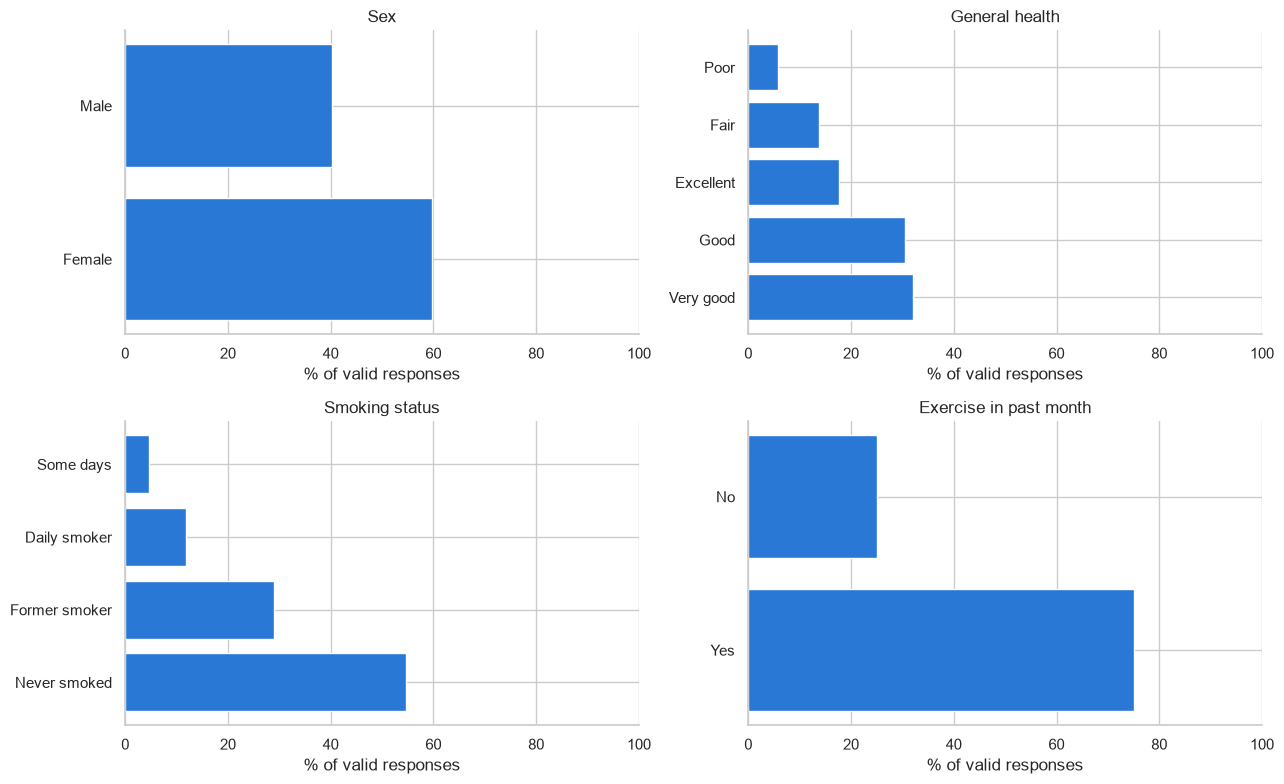

In [10]:
labels = {
    'SEX': {1: 'Male', 2: 'Female'},
    'GENHLTH': {
        1: 'Excellent', 2: 'Very good',
        3: 'Good', 4: 'Fair', 5: 'Poor'
    },
    '_SMOKER3': {
        1: 'Daily smoker',
        2: 'Some days',
        3: 'Former smoker',
        4: 'Never smoked'
    },
    'EXERANY2': {1: 'Yes', 2: 'No'}
}

for col, mapping in labels.items():
    d[col + '_label'] = d[col].map(mapping)

plot_cols = [
    'SEX_label', 'GENHLTH_label',
    '_SMOKER3_label', 'EXERANY2_label'
]

titles = [
    'Sex', 'General health',
    'Smoking status', 'Exercise in past month'
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, col, title in zip(axes.flat, plot_cols, titles):
    vc = d[col].value_counts(normalize=True) * 100

    ax.barh(vc.index.astype(str), vc.values, color=BLUE)
    ax.set(title=title, xlabel='% of valid responses', xlim=(0, 100))

plt.tight_layout()
plt.show()

### Remark

The complete diagnostic report shows:

- **283,950 female** respondents and **191,737 male** respondents.
- **254,492** respondents coded as never smokers.
- **355,588** respondents reported exercising in the previous month.

These are unweighted survey counts, not necessarily estimates of the US population.

The BRFSS survey weight `_LLCPWT` should be considered when estimating population-level percentages.

## 9. Age distribution

The variable `_AGEG5YR` divides respondents into age groups.

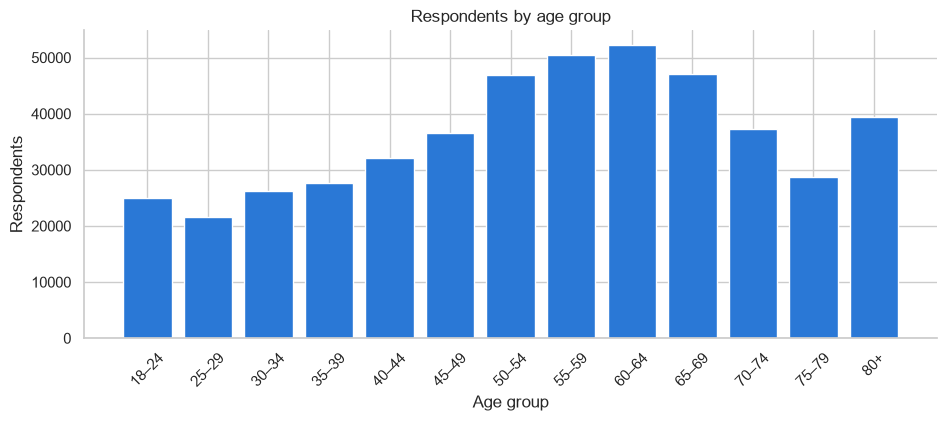

In [11]:
age_labels = [
    '18–24', '25–29', '30–34', '35–39',
    '40–44', '45–49', '50–54', '55–59',
    '60–64', '65–69', '70–74', '75–79', '80+'
]

age_map = dict(enumerate(age_labels, start=1))

d['Age_group'] = pd.Categorical(
    d['_AGEG5YR'].map(age_map),
    categories=age_labels,
    ordered=True
)

vc = d['Age_group'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(vc.index.astype(str), vc.values, color=BLUE)

ax.set(
    title='Respondents by age group',
    xlabel='Age group',
    ylabel='Respondents'
)

plt.xticks(rotation=45)
plt.show()

### Observation

The diagnostic report shows that the largest age-group count is **60–64 years**, with **52,265 respondents**.

The dataset contains respondents from a broad range of ages, but age groups are not represented equally.

**Interpretation:** Age may be an important explanatory variable for diabetes. Raw survey distributions should not be interpreted as population age distributions without considering survey weights.

## 10. Correlation analysis

Spearman correlation measures the strength and direction of a monotonic relationship.

Values range from -1 to +1:
- Close to +1: strong positive association
- Close to -1: strong negative association
- Close to 0: weak monotonic association

Correlation does not prove causation.

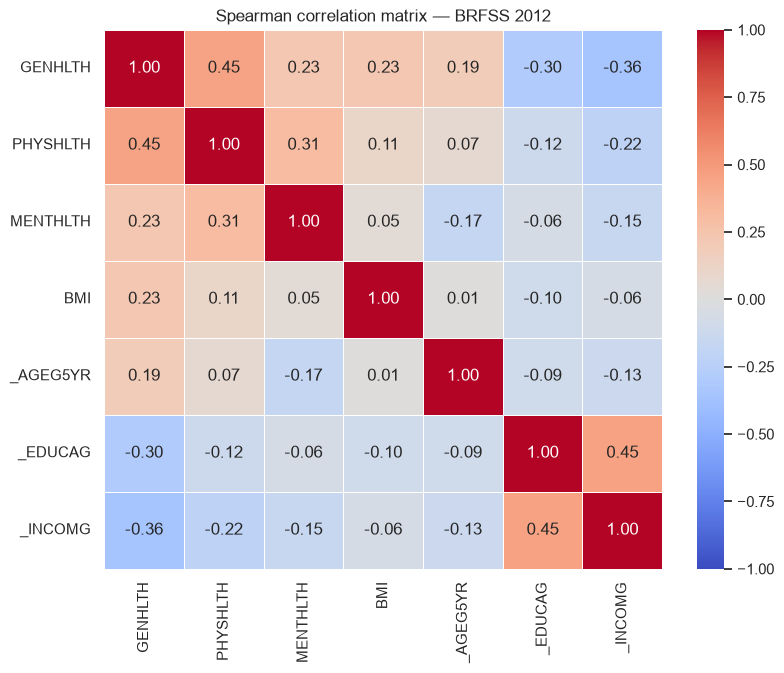

In [12]:
corr_cols = [
    'GENHLTH', 'PHYSHLTH', 'MENTHLTH',
    'BMI', '_AGEG5YR', '_EDUCAG', '_INCOMG'
]

corr = d[corr_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=.5,
    ax=ax
)

ax.set_title('Spearman correlation matrix — BRFSS 2012')
plt.show()

### Observation

The earlier diagnostic sample of 9,514 respondents produced:

| Relationship | Spearman r |
|---|---:|
| General health / poor physical health days | +0.453 |
| General health / income group | -0.353 |
| General health / education | -0.302 |
| Education / income | +0.451 |
| Physical / mental poor-health days | +0.311 |

Higher `GENHLTH` codes indicate worse self-rated health.

Thus, the positive association with poor physical-health days is consistent with the variable definitions.

The negative associations with income and education suggest that respondents in higher groups tend to report better general health.

**Note:** The heatmap above recalculates these relationships using all available respondents, so its coefficients may differ slightly from the diagnostic sample.

## 11. General health by income group

We compare self-rated health across income groups using row-normalized percentages.

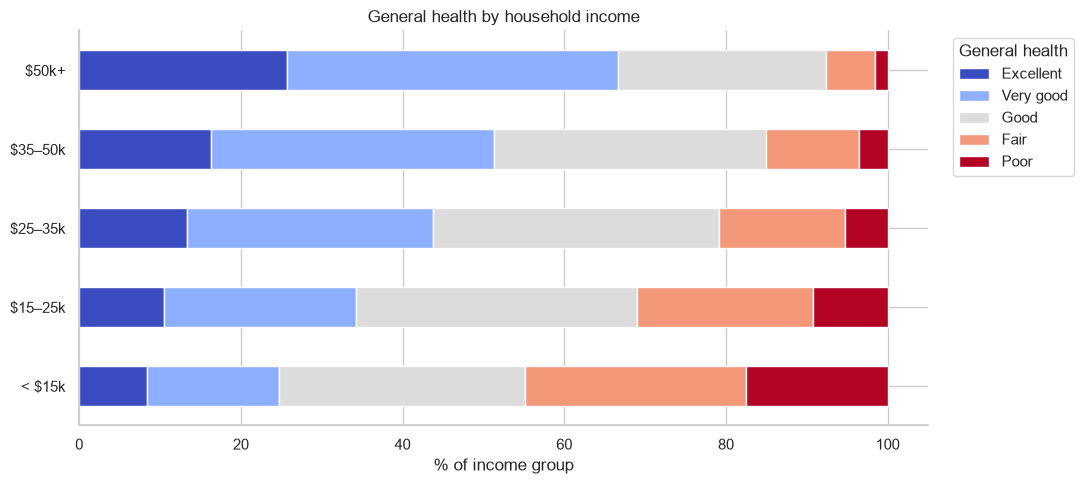

In [13]:
income_labels = {
    1: '< $15k',
    2: '$15–25k',
    3: '$25–35k',
    4: '$35–50k',
    5: '$50k+'
}

d['Income_group'] = d['_INCOMG'].map(income_labels)

health_order = [
    'Excellent', 'Very good', 'Good', 'Fair', 'Poor'
]

income_order = list(income_labels.values())

ct = pd.crosstab(
    d['Income_group'],
    d['GENHLTH_label'],
    normalize='index'
).reindex(index=income_order, columns=health_order) * 100

ax = ct.plot(
    kind='barh',
    stacked=True,
    figsize=(11, 5),
    colormap='coolwarm',
    edgecolor='white'
)

ax.set(
    title='General health by household income',
    xlabel='% of income group',
    ylabel=''
)

ax.legend(
    title='General health',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

### Remark

This chart shows how the distribution of self-reported health changes across income groups.

Compare the proportions reporting *Excellent* or *Very good* health with the proportions reporting *Fair* or *Poor* health.

The diagnostic correlation suggested an association between income and health, but the chart provides a more interpretable view of that relationship.

This is observational survey data; the relationship does not establish a causal effect of income on health.

## 12. BMI and diabetes status

We compare the BMI distribution for respondents reporting no diabetes, pre-diabetes, and diabetes.

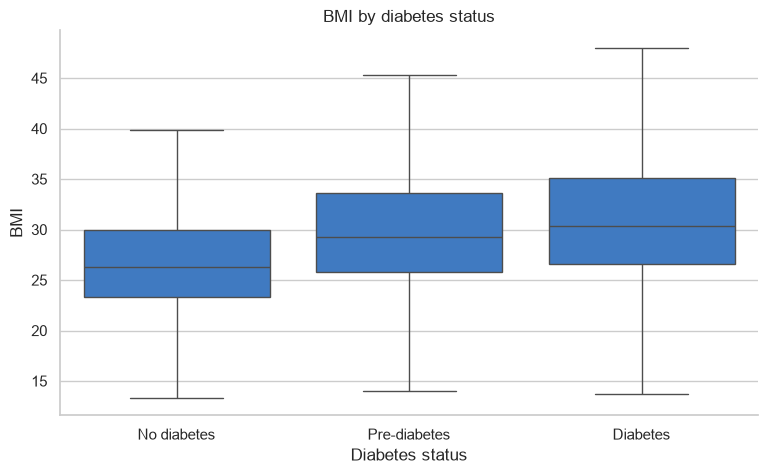

,count,mean,median,std
Diabetes_status,,,,
Diabetes,56430,31.50,30.34,7.14
No diabetes,382051,27.11,26.32,5.62
Pre-diabetes,7410,30.20,29.26,6.65


In [14]:
sub = d[d['Diabetes_status'].isin([
    'No diabetes', 'Pre-diabetes', 'Diabetes'
])]

fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=sub,
    x='Diabetes_status',
    y='BMI',
    order=['No diabetes', 'Pre-diabetes', 'Diabetes'],
    color=BLUE,
    showfliers=False,
    ax=ax
)

ax.set(
    title='BMI by diabetes status',
    xlabel='Diabetes status',
    ylabel='BMI'
)

plt.show()

display(
    sub.groupby('Diabetes_status')['BMI']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

### Observation

The diagnostic **2% sample** showed the following mean BMI values:

| Diabetes category | Mean BMI |
|---|---:|
| No diabetes | 27.09 |
| Pre-diabetes | 29.71 |
| Diabetes | 31.19 |

**Interpretation:** Respondents reporting diabetes had a higher average BMI than those reporting no diabetes in the diagnostic sample.

The boxplot above uses the complete dataset and allows this relationship to be examined more reliably.

These distributions overlap, so BMI alone cannot determine an individual's diabetes status.

## 13. Diabetes prevalence by age group

This analysis examines the proportion of valid respondents in each age group who report diabetes.

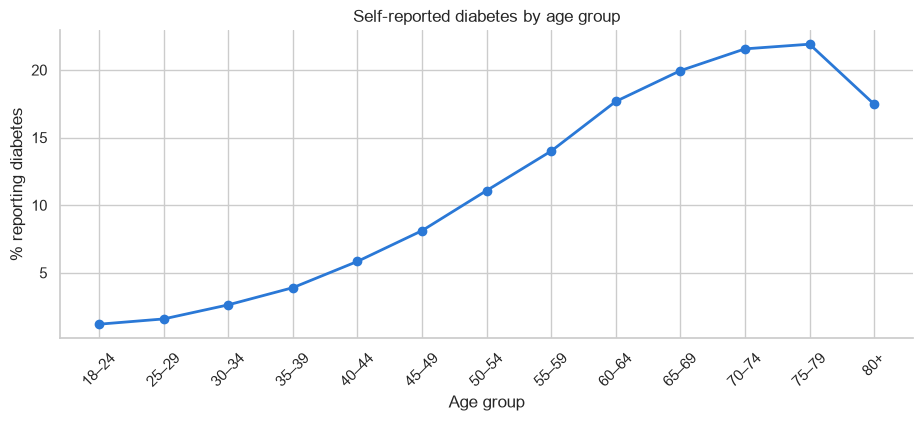

In [15]:
age_diabetes = (
    d.dropna(subset=['Age_group', 'DIABETE3'])
    .groupby('Age_group', observed=True)['DIABETE3']
    .apply(lambda x: (x == 1).mean() * 100)
)

fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(
    age_diabetes.index.astype(str),
    age_diabetes.values,
    marker='o',
    color=BLUE,
    linewidth=2
)

ax.set(
    title='Self-reported diabetes by age group',
    xlabel='Age group',
    ylabel='% reporting diabetes'
)

plt.xticks(rotation=45)
plt.show()

### Remark

This graph helps identify how reported diabetes varies with age.

Percentages are calculated within each age group, rather than using raw counts, making the age groups more comparable.

These are still unweighted sample percentages.

## 14. Respondents by state

`_STATE` contains state or territory FIPS codes.

States/territories represented: 53
Median respondents per state: 7,788


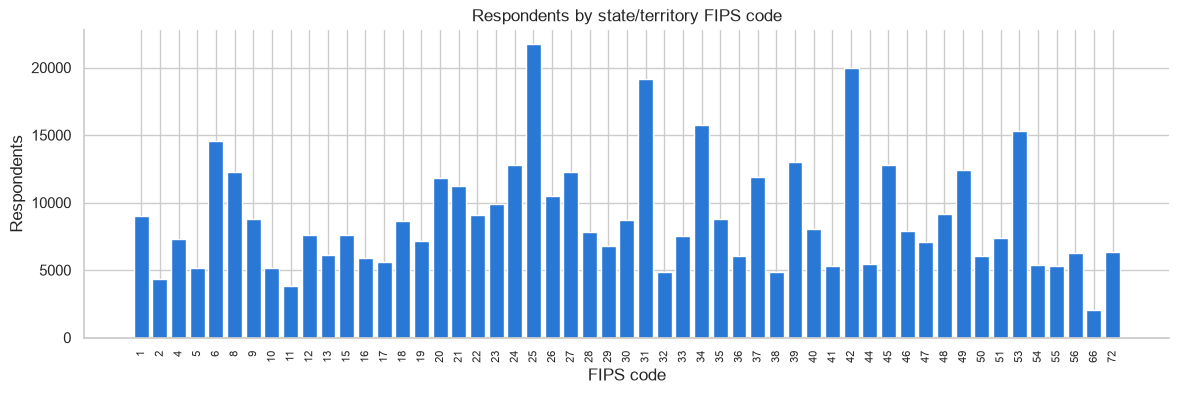

In [16]:
state_counts = df['_STATE'].value_counts().sort_index()

print(f'States/territories represented: {len(state_counts)}')
print(f'Median respondents per state: {state_counts.median():,.0f}')

fig, ax = plt.subplots(figsize=(14, 4))

ax.bar(
    state_counts.index.astype(int).astype(str),
    state_counts.values,
    color=BLUE
)

ax.set(
    title='Respondents by state/territory FIPS code',
    xlabel='FIPS code',
    ylabel='Respondents'
)

ax.tick_params(axis='x', rotation=90, labelsize=8)
plt.show()

### Observation

The diagnostic report identified **53 state/territory codes**.

The largest respondent counts included:
- FIPS 25: 21,723
- FIPS 42: 19,958
- FIPS 31: 19,173

Different respondent counts do not necessarily indicate different population sizes or diabetes prevalence.

Survey weights and sampling design are important for geographic comparisons.

## 15. Data-quality checks

### 15.1 Missing values after decoding

The original dataset's 51.45% missingness does not include all special missing-value codes.

We now inspect missingness in the selected, decoded features.

,Missing (%)
_INCOMG,14.03
BMI,5.36
PHYSHLTH,2.08
_SMOKER3,2.03
MENTHLTH,1.69
_AGEG5YR,0.96
CVDINFR4,0.44
_EDUCAG,0.40
GENHLTH,0.33
EXERANY2,0.33


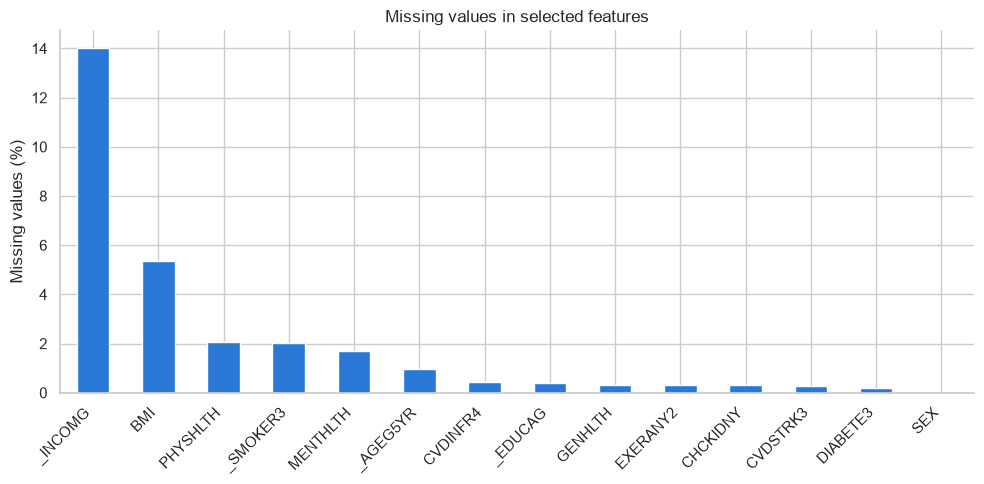

In [17]:
selected = [
    'GENHLTH', 'PHYSHLTH', 'MENTHLTH',
    'BMI', 'SEX', '_AGEG5YR',
    '_EDUCAG', '_INCOMG', '_SMOKER3',
    'DIABETE3', 'EXERANY2',
    'CVDINFR4', 'CVDSTRK3', 'CHCKIDNY'
]

selected_missing = (
    d[selected].isna().mean() * 100
).sort_values(ascending=False)

display(selected_missing.to_frame('Missing (%)').round(2))

fig, ax = plt.subplots(figsize=(10, 5))

selected_missing.plot(kind='bar', color=BLUE, ax=ax)

ax.set(
    title='Missing values in selected features',
    ylabel='Missing values (%)'
)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 15.2 Duplicate rows

We inspect duplicates in the complete dataset and separately in the selected health variables.

Repeated health-answer patterns do not necessarily represent duplicate people.

In [18]:
print('Exact duplicate full rows:', df.duplicated().sum())
print('Repeated selected-answer patterns:',
      d[selected].duplicated().sum())

Exact duplicate full rows: 0
Repeated selected-answer patterns: 37670


### 15.3 Redundant variables

Some BRFSS variables contain closely related information.

Examples:
- `EDUCA` and `_EDUCAG`
- `INCOME2` and `_INCOMG`
- `SMOKE100` and `_SMOKER3`
- `EXERANY2` and `_TOTINDA`

Using both a raw answer and its derived category can introduce unnecessary redundancy.

**Decision:** Compare these variables and select an appropriate representation before modeling.

In [19]:
pairs = [
    ('EDUCA', '_EDUCAG'),
    ('INCOME2', '_INCOMG'),
    ('EXERANY2', '_TOTINDA'),
    ('SMOKE100', '_SMOKER3')
]

for a, b in pairs:
    if a in df.columns and b in df.columns:
        r = df[[a, b]].corr(method='spearman').iloc[0, 1]
        print(f'{a} vs {b}: Spearman r = {r:.3f}')

EDUCA vs _EDUCAG: Spearman r = 1.000
INCOME2 vs _INCOMG: Spearman r = 0.979
EXERANY2 vs _TOTINDA: Spearman r = 1.000
SMOKE100 vs _SMOKER3: Spearman r = 0.955


## 16. EDA conclusions

### Dataset structure
The BRFSS 2012 dataset contains **475,687 respondents and 359 variables**.

### Missing values
The original dataset contains **51.45% missing cells**, largely because many survey questions are conditional or belong to optional modules.

### Special codes
BRFSS special codes must be interpreted before calculating statistics. In particular, `88` means zero days for the physical- and mental-health questions.

### Diabetes distribution
The target is highly imbalanced, with approximately **84.78%** of respondents reporting no diabetes and **1.63%** reporting pre-diabetes.

### Health relationships
The diagnostic sample found meaningful associations between general health, physical-health days, education, and income.

### BMI and diabetes
The diagnostic sample showed higher average BMI among respondents reporting diabetes than among those reporting no diabetes.

### Important limitations
- Survey responses are self-reported.
- The data are observational, not causal.
- Some diagnostic statistics came from a 2% sample.
- Unweighted counts do not necessarily represent US population proportions.
- Variable definitions and special codes should be checked against the official BRFSS 2012 documentation.

### Next steps for machine learning
1. Define and justify the target classes.
2. Select relevant predictive features.
3. Exclude variables that directly reveal the diabetes diagnosis.
4. Split the data into training and testing sets.
5. Fit missing-value imputation and encoding on training data only.
6. Address class imbalance without leaking information from the test set.
7. Train and evaluate classification models using class-specific metrics.

**Final conclusion:** BRFSS 2012 provides a large and informative dataset for studying diabetes prediction. However, careful variable selection, special-code handling, and class-imbalance management are essential before building a reliable classification model.

In [21]:

import pandas as pd
import numpy as np
from pathlib import Path

# ==========================================
# BRFSS 2012 - PREPARATION DIAGNOSTICS
# ==========================================

raw = pd.read_csv("2012.csv", low_memory=False)
df = raw.copy()

report = []

def log(title, value):
    report.append(f"\n{'=' * 60}\n{title}\n{'=' * 60}\n{value}\n")

# STEP 0: Original dataset
log("STEP 0 - ORIGINAL DATASET", df.shape)

# STEP 1: Target
log(
    "STEP 1 - TARGET BEFORE CLEANING",
    df["DIABETE3"].value_counts(dropna=False)
)

df = df[df["DIABETE3"].isin([1, 2, 3, 4])].copy()
df["target"] = df["DIABETE3"].map({
    3: 0, 2: 0, 4: 1, 1: 2
}).astype(int)

log("TARGET AFTER CLEANING", df["target"].value_counts())
log("SHAPE AFTER TARGET CLEANING", df.shape)

# STEP 2: Feature selection
features = [
    "_BMI5", "_BMI5CAT", "GENHLTH",
    "PHYSHLTH", "MENTHLTH",
    "CVDSTRK3", "CVDINFR4", "CVDCRHD4",
    "CHCKIDNY", "CHCCOPD1", "HAVARTH3",
    "ADDEPEV2", "ASTHMA3",
    "_SMOKER3", "SMOKE100",
    "EXERANY2", "_TOTINDA", "_RFDRHV4",
    "HLTHPLN1", "MEDCOST",
    "SEX", "_AGEG5YR", "EDUCA",
    "_EDUCAG", "INCOME2", "_INCOMG",
    "MARITAL"
]

available = [c for c in features if c in df.columns]
unavailable = [c for c in features if c not in df.columns]

log("STEP 2 - AVAILABLE FEATURES", available)
log("UNAVAILABLE FEATURES", unavailable)

log(
    "COLUMNS MORE THAN 50% MISSING",
    (df.isna().mean() > 0.5).sum()
)

log(
    "COLUMNS MORE THAN 90% MISSING",
    (df.isna().mean() > 0.9).sum()
)

df = df[available + ["target"]].copy()

# STEP 4: Special codes
special_codes = {
    "GENHLTH": [7, 9],
    "PHYSHLTH": [77, 99],
    "MENTHLTH": [77, 99],
    "CVDSTRK3": [7, 9],
    "CVDINFR4": [7, 9],
    "CVDCRHD4": [7, 9],
    "CHCKIDNY": [7, 9],
    "CHCCOPD1": [7, 9],
    "HAVARTH3": [7, 9],
    "ADDEPEV2": [7, 9],
    "ASTHMA3": [7, 9],
    "_SMOKER3": [9],
    "SMOKE100": [7, 9],
    "EXERANY2": [7, 9],
    "_TOTINDA": [9],
    "_RFDRHV4": [9],
    "HLTHPLN1": [7, 9],
    "MEDCOST": [7, 9],
    "_AGEG5YR": [14],
    "EDUCA": [9],
    "_EDUCAG": [9],
    "INCOME2": [77, 99],
    "_INCOMG": [9],
    "MARITAL": [9]
}

special_codes = {
    c: codes for c, codes in special_codes.items()
    if c in df.columns
}

hidden = pd.Series({
    c: df[c].isin(codes).sum()
    for c, codes in special_codes.items()
})

log(
    "STEP 4 - HIDDEN MISSING VALUES",
    hidden.sort_values(ascending=False)
)

for c, codes in special_codes.items():
    df[c] = df[c].replace(codes, np.nan)

for c in ["PHYSHLTH", "MENTHLTH"]:
    if c in df.columns:
        df[c] = df[c].replace(88, 0)

# STEP 3: Redundancy
corr = df[available].corr(method="spearman").abs()

pairs = corr.where(
    np.triu(np.ones(corr.shape, dtype=bool), k=1)
).stack()

log(
    "STEP 3 - HIGH CORRELATIONS (> 0.8)",
    pairs[pairs > 0.8].sort_values(ascending=False)
)

redundant = [
    "_BMI5CAT", "EDUCA", "INCOME2",
    "SMOKE100", "EXERANY2"
]

df = df.drop(columns=redundant, errors="ignore")

features = [c for c in available if c not in redundant]

log("FEATURES AFTER REDUNDANCY REMOVAL", features)
log("DUPLICATE ANSWER PATTERNS", df.duplicated().sum())

# STEP 5: Missing values
missing = df[features].isna().mean().sort_values(ascending=False)

log("STEP 5 - MISSING VALUES BY FEATURE", missing)

row_missing = df[features].isna().mean(axis=1)

log("MISSING VALUES PER ROW", row_missing.describe())
log("ROWS MORE THAN 50% MISSING", (row_missing > 0.5).sum())

missing_by_class = (
    df.groupby("target")[features]
    .apply(lambda g: g.isna().mean())
    .T
)

log("MISSING VALUES BY TARGET CLASS", missing_by_class)

df = df.loc[row_missing <= 0.5].copy()
log("SHAPE AFTER ROW FILTERING", df.shape)

# STEP 6: BMI conversion
df["BMI"] = df["_BMI5"] / 100
df = df.drop(columns="_BMI5")

features = ["BMI" if c == "_BMI5" else c for c in features]

numeric_cols = ["BMI", "PHYSHLTH", "MENTHLTH"]

log(
    "STEP 6 - NUMERIC STATISTICS",
    df[numeric_cols].describe()
)

# STEP 7: Outliers
q1, q3 = df["BMI"].quantile([0.25, 0.75])
iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

log("STEP 7 - BMI IQR LIMITS", (low, high))

log(
    "BMI VALUES OUTSIDE IQR",
    ((df["BMI"] < low) | (df["BMI"] > high)).sum()
)

log(
    "BMI VALUES OUTSIDE 12-80",
    ((df["BMI"] < 12) | (df["BMI"] > 80)).sum()
)

df.loc[
    (df["BMI"] < 12) | (df["BMI"] > 80),
    "BMI"
] = np.nan

log("BMI AFTER OUTLIER HANDLING", df["BMI"].describe())

# STEP 8: Class balance
log("STEP 8 - TARGET COUNTS", df["target"].value_counts())

log(
    "TARGET PROPORTIONS",
    df["target"].value_counts(normalize=True)
)

# STEP 9: Features vs target
log(
    "STEP 9 - NUMERIC MEANS BY TARGET",
    df.groupby("target")[numeric_cols].mean()
)

strength = (
    df[features]
    .corrwith(df["target"], method="spearman")
    .abs()
    .sort_values(ascending=False)
)

log("FEATURE CORRELATIONS WITH TARGET", strength)

log(
    "NEAR-CONSTANT FEATURES (>95%)",
    pd.Series({
        c: df[c].value_counts(normalize=True).iloc[0]
        for c in features
        if df[c].notna().any()
    }).loc[lambda s: s > 0.95]
)

# STEP 10: Feature values for encoding
for c in features:
    if c not in numeric_cols:
        log(
            f"STEP 10 - VALUES: {c}",
            df[c].value_counts(dropna=False).head(20)
        )

# Final diagnostic summary
log("FINAL SHAPE BEFORE ENCODING", df.shape)

output = Path("preparation_diagnostics_2012.txt")
output.write_text(
    "\n".join(map(str, report)),
    encoding="utf-8"
)

print("Diagnostic report generated!")
print("File:", output.resolve())


Diagnostic report generated!
File: C:\Users\HP\Desktop\ProjetML\preparation_diagnostics_2012.txt
